# CrewAI multi-crew setup with Pydantic

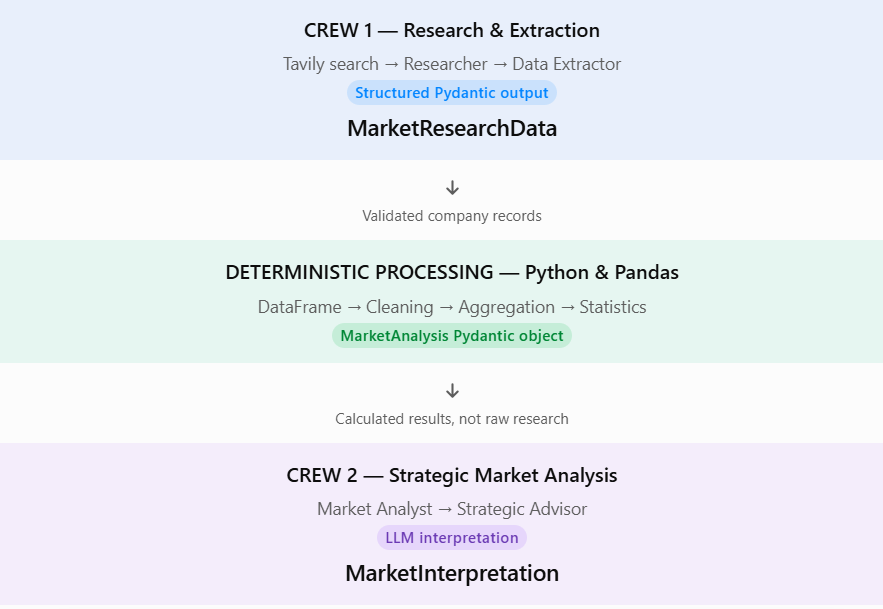

In [ ]:
!uv pip install "crewai[litellm]" crewai_tools

In [ ]:
! uv pip install tavily-python

In [ ]:
# Warning control
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import os
from google.colab import userdata

os.environ["OPENROUTER_API_KEY"] = userdata.get('OPENROUTER_API_KEY')
os.environ["OPENAI_API_BASE"] = "https://openrouter.ai/api/v1"

In [ ]:
os.environ['TAVILY_API_KEY']=userdata.get('TAVILY_API_KEY')

In [ ]:
from crewai import LLM
llm = LLM(
    model="openrouter/openai/gpt-4o-mini",
    temperature=0.1
)

In [ ]:
# from google.colab import userdata
# import os
# from crewai import LLM

# os.environ['GEMINI_API_KEY']=userdata.get('GEMINI_API_KEY')

# llm = LLM(
#     model="gemini/gemini-3.5-flash-lite",
# )

In [ ]:
# from google.colab import userdata
# import os
# from crewai import LLM

# os.environ['OPENAI_API_KEY']=userdata.get('OPENAI_API_KEY')

# llm = LLM(
#     model="gpt-4o-mini",
#     temperature=0.1
# )

In [ ]:
from crewai_tools import TavilySearchTool

search_tool = TavilySearchTool()

In [ ]:
from crewai import Agent, Task, Crew

In [ ]:
from pydantic import BaseModel, Field, field_validator
from typing import Optional
from urllib.parse import urlsplit


class CompanyData(BaseModel):
    name: str
    country: str
    industry: str

    revenue_millions: Optional[float] = Field(
        default=None, ge=0
    )

    employees: Optional[int] = Field(
        default=None, ge=0
    )

    revenue_growth_pct: Optional[float] = None

    # Use str instead of HttpUrl for LLM-compatible JSON Schema
    source_url: str

    reporting_period: Optional[str] = None
    currency: Optional[str] = None

    @field_validator("source_url")
    @classmethod
    def validate_source_url(cls, value: str) -> str:
        parsed = urlsplit(value)

        if parsed.scheme not in ("http", "https") or not parsed.netloc:
            raise ValueError("A valid HTTP or HTTPS URL is required")

        return value


class MarketResearchData(BaseModel):
    topic: str
    companies: list[CompanyData]


class MarketAnalysis(BaseModel):
    companies_analysed: int
    average_revenue_millions: Optional[float]
    average_growth_pct: Optional[float]
    largest_company: Optional[str]
    fastest_growing_company: Optional[str]
    industry_distribution: dict[str, int]
    data_quality_notes: list[str]


class MarketInterpretation(BaseModel):
    executive_summary: str
    market_patterns: list[str]
    opportunities: list[str]
    risks: list[str]
    strategic_recommendations: list[str]

In [ ]:
# Agent 1
market_researcher = Agent(
    role="Market Researcher",
    goal="Find relevant European AI companies and reliable market information",
    backstory=(
        "You are an experienced market researcher. "
        "You search for credible sources, company reports, "
        "and publicly available financial information."
    ),
    tools=[search_tool],
    llm=llm,
    verbose=True
)

# Agent 2
data_extractor = Agent(
    role="Financial Data Extraction Specialist",
    goal="Extract comparable company information from research sources",
    backstory=(
        "You specialize in extracting structured company "
        "and financial information from reliable sources. "
        "You never invent missing financial values."
    ),
    llm=llm,
    verbose=True
)

In [ ]:
research_task = Task(
    description="""
    Research the European AI market.

    Identify 10 relevant European AI companies.

    Find information about:
    - Company name
    - Country
    - Industry
    - Latest publicly available annual revenue
    - Employee count
    - Revenue growth

    Search for reliable sources such as company annual
    reports, official company websites and reputable
    financial publications.

    Record the source URL for each company.
    Prefer the latest available annual reporting period.
    Do not invent missing information.
    """,
    expected_output=(
        "Research findings covering 10 European AI companies "
        "with source references."
    ),
    agent=market_researcher
)

extraction_task = Task(
    description="""
    Using the research findings, extract the company data.

    Requirements:
    - Revenue must be expressed in EUR millions.
    - Revenue growth must be expressed as a percentage.
    - Employee count must be an integer.
    - Preserve the reporting period.
    - Record a source URL for each company.
    - Use null for unavailable values.
    - Do not estimate missing values.

    Return the extracted information in the required schema.
    """,
    expected_output="A validated collection of company records.",
    agent=data_extractor,
    output_pydantic=MarketResearchData
)

In [ ]:
research_crew = Crew(
    agents=[
        market_researcher,
        data_extractor
    ],
    tasks=[
        research_task,
        extraction_task
    ],
    verbose=True
)

In [ ]:
import nest_asyncio
nest_asyncio.apply()

async def run_crew():
    return await research_crew.kickoff_async(inputs={
        "topic": "European AI market"
        }
)

result = await run_crew()

In [ ]:
import pandas as pd

# Retrieve validated Pydantic output
research_data = result.pydantic

if research_data is None:
    raise ValueError("Crew 1 failed to produce valid structured data")

# Convert Pydantic objects into a DataFrame
df = pd.DataFrame([
    company.model_dump(mode="json")
    for company in research_data.companies
])

print(df.head())

In [ ]:
# Convert numeric columns
numeric_columns = [
    "revenue_millions",
    "employees",
    "revenue_growth_pct"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

# Remove duplicate companies
duplicates = df.duplicated(
    subset=["name"],
    keep="first"
).sum()

df = df.drop_duplicates(
    subset=["name"],
    keep="first"
).reset_index(drop=True)

# --------------------------------
# Deterministic calculations
# --------------------------------

revenue_data = df["revenue_millions"].dropna()
growth_data = df["revenue_growth_pct"].dropna()

# Average revenue
average_revenue = (
    round(float(revenue_data.mean()), 2)
    if not revenue_data.empty else None
)

# Average revenue growth
average_growth = (
    round(float(growth_data.mean()), 2)
    if not growth_data.empty else None
)

# Largest company by revenue
largest_company = None

if not revenue_data.empty:
    largest_index = df["revenue_millions"].idxmax()
    largest_company = df.loc[largest_index, "name"]

# Fastest-growing company
fastest_growing_company = None

if not growth_data.empty:
    growth_index = df["revenue_growth_pct"].idxmax()
    fastest_growing_company = df.loc[growth_index, "name"]

# Industry distribution
industry_distribution = {
    str(key): int(value)
    for key, value in
    df["industry"].fillna("Unspecified").value_counts().items()
}

# --------------------------------
# Data quality assessment
# --------------------------------

data_quality_notes = []

if duplicates:
    data_quality_notes.append(
        f"{duplicates} duplicate company records were removed."
    )

missing_revenue = int(df["revenue_millions"].isna().sum())
missing_growth = int(df["revenue_growth_pct"].isna().sum())
missing_employees = int(df["employees"].isna().sum())

if missing_revenue:
    data_quality_notes.append(
        f"Revenue information missing for {missing_revenue} companies."
    )

if missing_growth:
    data_quality_notes.append(
        f"Revenue growth missing for {missing_growth} companies."
    )

if missing_employees:
    data_quality_notes.append(
        f"Employee information missing for {missing_employees} companies."
    )

if not data_quality_notes:
    data_quality_notes.append(
        "No missing values or duplicate company records detected."
    )

# --------------------------------
# Construct Pydantic analysis object
# --------------------------------

market_analysis = MarketAnalysis(
    companies_analysed=len(df),
    average_revenue_millions=average_revenue,
    average_growth_pct=average_growth,
    largest_company=largest_company,
    fastest_growing_company=fastest_growing_company,
    industry_distribution=industry_distribution,
    data_quality_notes=data_quality_notes
)

print("\nDeterministic market analysis:")
print(market_analysis.model_dump_json(indent=2))

print("\nProcessed DataFrame:")
display(df)

In [ ]:
# --------------------------------
# Serialize Pandas analysis output
# --------------------------------

analysis_json = market_analysis.model_dump_json(indent=2)


# --------------------------------
# Crew 2 agents
# --------------------------------

market_analyst = Agent(
    role="Senior Market Analyst",
    goal=(
        "Interpret market statistics and identify "
        "meaningful patterns in the European AI market."
    ),
    backstory=(
        "You are a senior market analyst specializing in "
        "the European technology sector. You interpret "
        "quantitative evidence, identify market patterns "
        "and distinguish evidence from assumptions."
    ),
    llm=llm,
    verbose=True,
    allow_delegation=False
)

strategic_advisor = Agent(
    role="Strategic Business Advisor",
    goal=(
        "Translate market analysis into actionable "
        "business opportunities and strategic recommendations."
    ),
    backstory=(
        "You are an experienced strategy consultant advising "
        "technology companies and investors. You develop "
        "evidence-based recommendations and identify market "
        "risks, opportunities and competitive implications."
    ),
    llm=llm,
    verbose=True,
    allow_delegation=False
)

In [ ]:
# --------------------------------
# Crew 2 tasks
# --------------------------------

market_analysis_task = Task(
    description=f"""
    Analyse the following structured market analysis.

    DATA:
    {analysis_json}

    Your responsibilities:

    1. Interpret the average company revenue.
    2. Evaluate average revenue growth.
    3. Consider the largest and fastest-growing companies.
    4. Interpret the industry distribution.
    5. Identify meaningful market patterns.
    6. Consider data quality limitations.

    Important:
    - Do not invent additional company statistics.
    - Do not recalculate the supplied statistics.
    - Distinguish observed patterns from assumptions.
    - Do not infer causality from descriptive statistics.

    Produce a concise analytical assessment.
    """,
    expected_output=(
        "A structured qualitative interpretation of the "
        "European AI market statistics."
    ),
    agent=market_analyst
)

strategy_task = Task(
    description="""
    Based on the market analyst's findings, develop a
    strategic assessment of the European AI market.

    Identify:

    1. Executive summary.
    2. Main market patterns.
    3. Potential business opportunities.
    4. Major market risks.
    5. Strategic recommendations.

    Recommendations should be grounded in the supplied
    market analysis.

    Do not invent market statistics or present assumptions
    as verified facts.

    Return the final result using the required Pydantic schema.
    """,
    expected_output=(
        "A structured strategic interpretation with an "
        "executive summary, patterns, opportunities, risks "
        "and recommendations."
    ),
    agent=strategic_advisor,
    context=[market_analysis_task],
    output_pydantic=MarketInterpretation
)



In [ ]:
analysis_crew = Crew(
    agents=[
        market_analyst,
        strategic_advisor
    ],
    tasks=[
        market_analysis_task,
        strategy_task
    ],
    verbose=True
)

In [ ]:
import nest_asyncio
nest_asyncio.apply()

async def run_analysis_crew():
    return await analysis_crew.kickoff_async()

interpretation_result = await run_analysis_crew()

In [ ]:
# --------------------------------
# Retrieve structured output
# --------------------------------

market_interpretation = interpretation_result.pydantic

if market_interpretation is None:
    raise ValueError(
        "Crew 2 failed to produce valid structured output"
    )

print("\nFINAL MARKET INTERPRETATION")

print(
    market_interpretation.model_dump_json(indent=2)
)

In [ ]:
# --------------------------------
# Generate Markdown report
# --------------------------------

def generate_markdown_report(result: MarketInterpretation) -> str:

    md = f"""
# European AI Market Analysis

## Executive Summary

{result.executive_summary}

## Market Patterns

"""

    for item in result.market_patterns:
        md += f"- {item}\n"

    md += "\n## Opportunities\n\n"

    for item in result.opportunities:
        md += f"- {item}\n"

    md += "\n## Risks\n\n"

    for item in result.risks:
        md += f"- {item}\n"

    md += "\n## Strategic Recommendations\n\n"

    for i, item in enumerate(
        result.strategic_recommendations, 1
    ):
        md += f"{i}. {item}\n"

    return md


# Generate report
markdown_report = generate_markdown_report(
    market_interpretation
)

# Display Markdown in Google Colab
from IPython.display import display, Markdown

display(Markdown(markdown_report))